"""
Customer Churn Analysis — Starter Project (Python)

This starter script uses pandas and matplotlib and common Python concepts to:
- Load the customer churn CSV (already generated as /mnt/data/customer_churn_dataset.csv)
- Clean and preprocess the data
- Perform EDA and visualizations (matplotlib)
- Implement useful helper functions (including separating ages of churned users)
- Feature-engineer, train a baseline Logistic Regression model, and evaluate it

Instructions:
- Place this file in the same environment where /mnt/data/customer_churn_dataset.csv is available
- Run with `python customer_churn_project_starter.py` or load the cells in a Jupyter notebook
- You can adapt/extend visualizations and models as needed

Author: ChatGPT — Starter template
"""



=== Data Overview ===
Rows, Columns: (2000, 14)

First 5 rows:
CustomerID       Name  Age Gender Region SubscriptionPlan  MonthlyCharges  TenureMonths  SupportTicketsRaised  UsageHoursPerWeek PaymentMethod   ContractType AutoRenewal Churn
  CUST1000 Customer_0   56 Female  North         Standard          504.57             3                     3               21.9    Debit Card Month-to-Month         Yes    No
  CUST1001 Customer_1   69   Male  South          Premium          537.55            37                     3               29.0        Wallet Month-to-Month          No    No
  CUST1002 Customer_2   46 Female  South            Basic          218.99            37                     5                9.1   Net Banking Month-to-Month         Yes    No
  CUST1003 Customer_3   32  Other   East         Standard          364.57             3                     0                7.2        Wallet Month-to-Month         Yes    No
  CUST1004 Customer_4   60   Male  North            Basi

C:\Users\ASUS\AppData\Local\Temp\ipykernel_13108\2391038573.py:52: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[c].fillna(median_val, inplace=True)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_13108\2391038573.py:52: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when

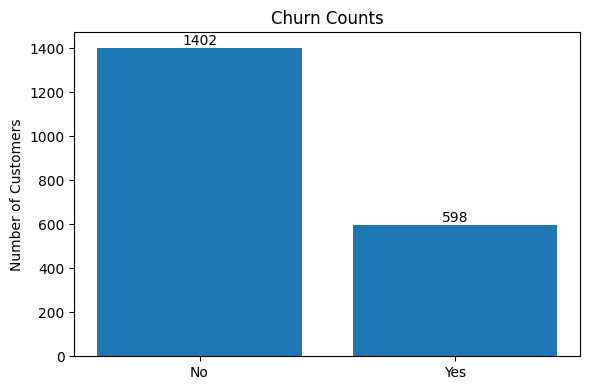

C:\Users\ASUS\AppData\Local\Temp\ipykernel_13108\2391038573.py:82: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = df.groupby('age_group')['ChurnFlag'].mean() * 100


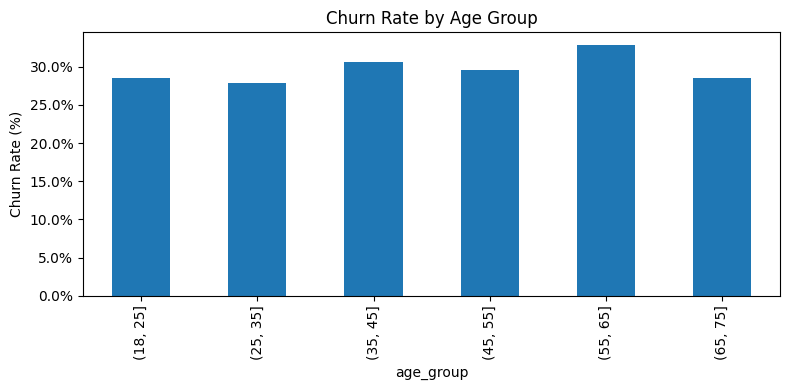

Churn ages saved to ./churn_outputs\churn_ages_series.csv


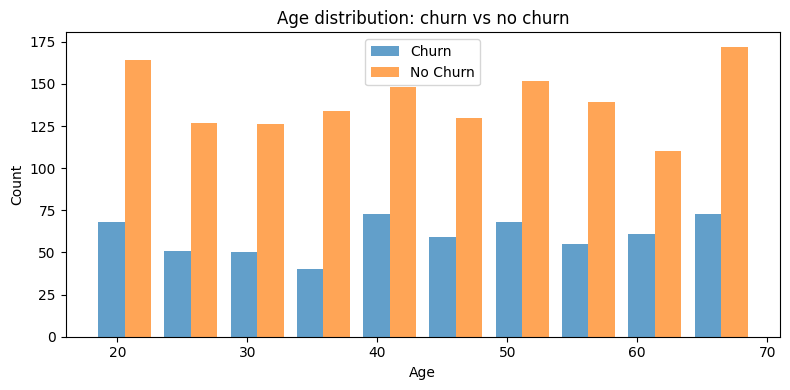


=== Baseline Logistic Regression Results ===
Accuracy: 0.702

Classification Report:
               precision    recall  f1-score   support

           0       0.70      1.00      0.82       351
           1       0.00      0.00      0.00       149

    accuracy                           0.70       500
   macro avg       0.35      0.50      0.41       500
weighted avg       0.49      0.70      0.58       500



C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize

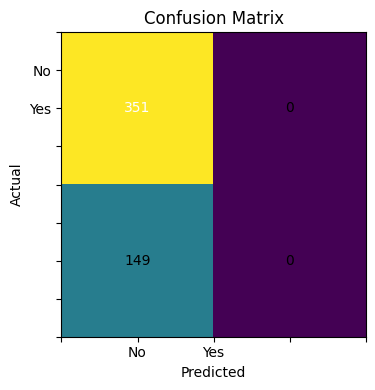

ROC AUC: 0.4582688005506797


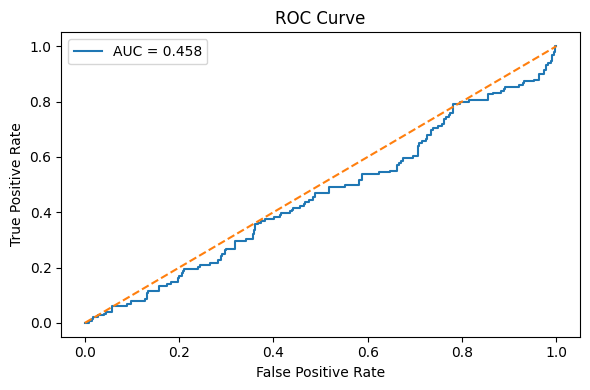

Model coefficients saved to ./churn_outputs\model_coefficients.csv

All outputs are in the ./churn_outputs folder


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, accuracy_score
import os

DATA_PATH = DATA_PATH = 'D:\\PYTHON\\Pandas\\customer_churn_dataset.csv'
OUTPUT_DIR = './churn_outputs'
RANDOM_STATE = 42

os.makedirs(OUTPUT_DIR, exist_ok=True)

def load_data(path=DATA_PATH):
    """Load CSV into a pandas DataFrame"""
    df = pd.read_csv(path)
    return df


def brief_overview(df):
    print('\n=== Data Overview ===')
    print('Rows, Columns:', df.shape)
    display = df.head(5)
    print('\nFirst 5 rows:')
    print(display.to_string(index=False))
    print('\nData types:')
    print(df.dtypes)
    print('\nMissing values per column:')
    print(df.isnull().sum())


def clean_data(df):
    """Basic cleaning: strip strings, fix types, handle outliers if simple rules apply"""
    df = df.copy()

    df.columns = [c.strip() for c in df.columns]

    num_cols = ['Age', 'MonthlyCharges', 'TenureMonths', 'SupportTicketsRaised', 'UsageHoursPerWeek']
    for c in num_cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors='coerce')

    if 'Churn' in df.columns:
        df['ChurnFlag'] = df['Churn'].map({'Yes': 1, 'No': 0})

    for c in num_cols:
        if c in df.columns:
            median_val = df[c].median()
            df[c].fillna(median_val, inplace=True)

    cat_cols = df.select_dtypes(include='object').columns.tolist()
    for c in cat_cols:
        df[c].fillna(df[c].mode()[0], inplace=True)

    return df



def plot_churn_distribution(df, save=True):
    counts = df['ChurnFlag'].value_counts().sort_index()
    labels = ['No', 'Yes']

    fig, ax = plt.subplots(figsize=(6,4))
    ax.bar(labels, counts.values)
    ax.set_title('Churn Counts')
    ax.set_ylabel('Number of Customers')
    for i, v in enumerate(counts.values):
        ax.text(i, v + max(counts.values)*0.01, str(v), ha='center')
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(OUTPUT_DIR, 'churn_counts.png'))
    plt.show()


def plot_churn_rate_by_age_group(df, bins=None, save=True):
    if bins is None:
        bins = [18,25,35,45,55,65,75]
    df['age_group'] = pd.cut(df['Age'], bins=bins)
    grouped = df.groupby('age_group')['ChurnFlag'].mean() * 100

    fig, ax = plt.subplots(figsize=(8,4))
    grouped.plot(kind='bar', ax=ax)
    ax.yaxis.set_major_formatter(PercentFormatter())
    ax.set_title('Churn Rate by Age Group')
    ax.set_ylabel('Churn Rate (%)')
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(OUTPUT_DIR, 'churn_rate_by_age_group.png'))
    plt.show()


def plot_monthly_churn_trend(df, date_col='TenureMonths', save=True):
    df_temp = df.copy()
    if 'JoinDate' in df_temp.columns:
        df_temp['JoinDate'] = pd.to_datetime(df_temp['JoinDate'])
        df_temp.set_index('JoinDate', inplace=True)
        churn_rate = df_temp['ChurnFlag'].resample('M').mean() * 100
        fig, ax = plt.subplots(figsize=(10,4))
        churn_rate.plot(ax=ax)
        ax.set_ylabel('Monthly churn rate (%)')
        ax.set_title('Monthly Churn Trend')
        ax.yaxis.set_major_formatter(PercentFormatter())
        plt.tight_layout()
        if save:
            plt.savefig(os.path.join(OUTPUT_DIR, 'monthly_churn_trend.png'))
        plt.show()
    else:
        print('No JoinDate column found — skipping monthly churn trend plot.')


def get_churn_ages(df):
    """Return a pandas Series of ages for churned customers and for non-churned customers."""
    churn_ages = df.loc[df['ChurnFlag'] == 1, 'Age'].reset_index(drop=True)
    nonchurn_ages = df.loc[df['ChurnFlag'] == 0, 'Age'].reset_index(drop=True)
    return churn_ages, nonchurn_ages


def prepare_features(df):
    """Create a simple feature set for modelling. Use one-hot encoding for categoricals and scale numerics."""
    df_model = df.copy()

    features = ['Age', 'MonthlyCharges', 'TenureMonths', 'SupportTicketsRaised', 'UsageHoursPerWeek']

    cat_to_encode = []
    for col in ['SubscriptionPlan', 'PaymentMethod', 'ContractType', 'Region', 'Gender']:
        if col in df_model.columns:
            cat_to_encode.append(col)

    df_model = pd.get_dummies(df_model, columns=cat_to_encode, drop_first=True)

    X = df_model[[c for c in df_model.columns if c in features or any(c.startswith(col + '_') for col in cat_to_encode)]]
    y = df_model['ChurnFlag']

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    return X_scaled, y, scaler, X.columns.tolist()


def train_baseline_model(X, y):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
    model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:,1]

    print('\n=== Baseline Logistic Regression Results ===')
    print('Accuracy:', accuracy_score(y_test, y_pred))
    print('\nClassification Report:\n', classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(5,4))
    im = ax.imshow(cm, interpolation='nearest')
    ax.set_title('Confusion Matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.xaxis.set_ticklabels([''] + ['No', 'Yes'])
    ax.yaxis.set_ticklabels([''] + ['No', 'Yes'])
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i,j] > cm.max()/2 else 'black')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'confusion_matrix.png'))
    plt.show()

    auc = roc_auc_score(y_test, y_proba)
    print('ROC AUC:', auc)
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    fig, ax = plt.subplots(figsize=(6,4))
    ax.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
    ax.plot([0,1],[0,1],'--')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title('ROC Curve')
    ax.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'roc_curve.png'))
    plt.show()

    return model


def run_all(path=DATA_PATH):
    df = load_data(path)
    brief_overview(df)
    df = clean_data(df)
    plot_churn_distribution(df)
    plot_churn_rate_by_age_group(df)

    churn_ages, nonchurn_ages = get_churn_ages(df)
    churn_ages.to_csv(os.path.join(OUTPUT_DIR, 'churn_ages_series.csv'), index=False)
    nonchurn_ages.to_csv(os.path.join(OUTPUT_DIR, 'nonchurn_ages_series.csv'), index=False)
    print(f'Churn ages saved to {os.path.join(OUTPUT_DIR, "churn_ages_series.csv")}')


    fig, ax = plt.subplots(figsize=(8,4))
    ax.hist([churn_ages, nonchurn_ages], bins=10, label=['Churn', 'No Churn'], density=False, alpha=0.7)
    ax.set_title('Age distribution: churn vs no churn')
    ax.set_xlabel('Age')
    ax.set_ylabel('Count')
    ax.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'age_distribution_churn_vs_nonchurn.png'))
    plt.show()

    X, y, scaler, feature_names = prepare_features(df)
    model = train_baseline_model(X, y)


    try:
        coef = model.coef_[0]
        coef_df = pd.DataFrame({'feature': feature_names, 'coefficient': coef})
        coef_df = coef_df.sort_values('coefficient', ascending=False)
        coef_df.to_csv(os.path.join(OUTPUT_DIR, 'model_coefficients.csv'), index=False)
        print('Model coefficients saved to', os.path.join(OUTPUT_DIR, 'model_coefficients.csv'))
    except Exception as e:
        print('Could not save coefficients:', e)

    print('\nAll outputs are in the', OUTPUT_DIR, 'folder')

if __name__ == '__main__':
    if not os.path.exists(DATA_PATH):
        print(f'ERROR: dataset not found at {DATA_PATH}. Please place your CSV at that path or update DATA_PATH.')
    else:
        run_all()


In [6]:
df

NameError: name 'df' is not defined

In [8]:
clean_data()

TypeError: clean_data() missing 1 required positional argument: 'df'